# Model Evaluation (Member 4)
**Goal:** Evaluate the 3 tuned models from Member 3 (Logistic Regression, Decision Tree, Random Forest) on the **same test set**.

Steps: load models + split -> predictions -> metrics -> confusion matrices -> comparison -> best model -> limitations.

Put `best_logreg.pkl`, `best_tree.pkl`, `best_rf.pkl` and `split_data.pkl` in the same folder as this notebook.

## 1. Load models and test data

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

models = {
    "Logistic Regression": joblib.load("best_logreg.pkl"),
    "Decision Tree": joblib.load("best_tree.pkl"),
    "Random Forest": joblib.load("best_rf.pkl"),
}
X_train, X_test, y_train, y_test = joblib.load("split_data.pkl")
print("Test size:", X_test.shape)
print(y_test.value_counts())

Test size: (130, 14)
Pass
1    110
0     20
Name: count, dtype: int64


## 2. Predictions

In [3]:
preds = {name: m.predict(X_test) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
train_preds = {name: m.predict(X_train) for name, m in models.items()}
print("done")

done


## 3. Accuracy, precision, recall, F1
Positive class = **Pass (1)**. 
- Accuracy: overall correct predictions
- Precision: of students predicted Pass, how many really passed
- Recall: of students who really passed, how many we found
- F1: balance of precision and recall

In [4]:
from sklearn.metrics import balanced_accuracy_score
rows = []
for name in models:
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1-score": f1_score(y_test, preds[name]),
        "ROC-AUC": roc_auc_score(y_test, probs[name]),
        "Fail recall": recall_score(y_test, preds[name], pos_label=0),
        "Balanced acc": balanced_accuracy_score(y_test, preds[name]),
        "Train F1": f1_score(y_train, train_preds[name]),
    })
metrics = pd.DataFrame(rows).set_index("Model").round(3)
metrics["F1 gap (train - test)"] = (metrics["Train F1"] - metrics["F1-score"]).round(3)

# baseline: always predict "Pass"
print("Baseline accuracy (predict everyone Pass):", round(y_test.mean(), 3))
metrics

Baseline accuracy (predict everyone Pass): 0.846


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Fail recall,Balanced acc,Train F1,F1 gap (train - test)
Model,,,,,,,,,
Logistic Regression,0.738,0.880,0.800,0.838,0.557,0.4,0.600,0.892,0.054
Decision Tree,0.715,0.848,0.809,0.828,0.505,0.2,0.505,1.000,0.172
Random Forest,0.746,0.867,0.827,0.847,0.580,0.3,0.564,1.000,0.153


In [5]:
for name in models:
    print("=" * 50)
    print(name)
    print(classification_report(y_test, preds[name], target_names=["Fail", "Pass"]))

Logistic Regression
              precision    recall  f1-score   support

        Fail       0.27      0.40      0.32        20
        Pass       0.88      0.80      0.84       110

    accuracy                           0.74       130
   macro avg       0.57      0.60      0.58       130
weighted avg       0.79      0.74      0.76       130

Decision Tree
              precision    recall  f1-score   support

        Fail       0.16      0.20      0.18        20
        Pass       0.85      0.81      0.83       110

    accuracy                           0.72       130
   macro avg       0.50      0.50      0.50       130
weighted avg       0.74      0.72      0.73       130

Random Forest
              precision    recall  f1-score   support

        Fail       0.24      0.30      0.27        20
        Pass       0.87      0.83      0.85       110

    accuracy                           0.75       130
   macro avg       0.55      0.56      0.56       130
weighted avg       0.77   

## 4. Confusion matrices

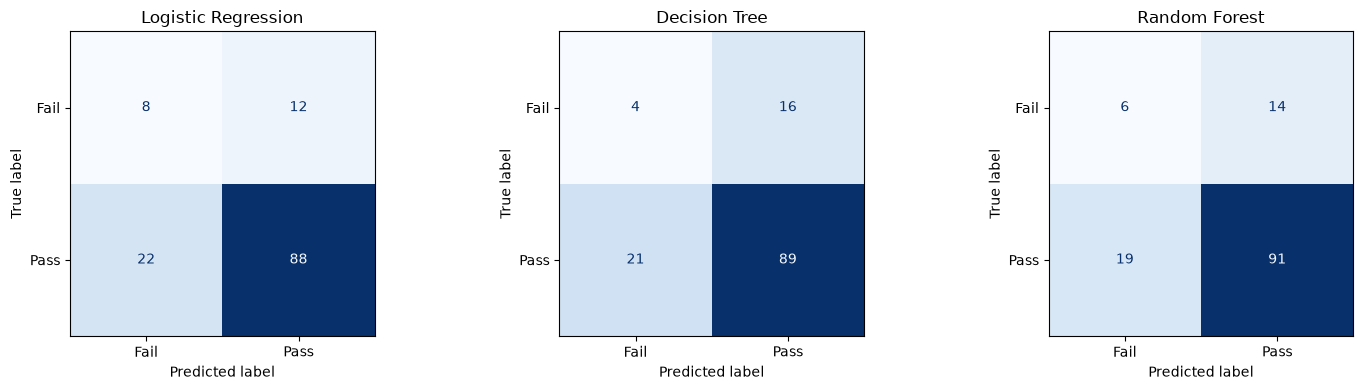

Logistic Regression: TN=8  FP=12  FN=22  TP=88
Decision Tree: TN=4  FP=16  FN=21  TP=89
Random Forest: TN=6  FP=14  FN=19  TP=91


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Fail", "Pass"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name}: TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**How to read it:**
- **FP** (predicted Pass, actually Fail): at-risk student missed, so no help given
- **FN** (predicted Fail, actually Pass): student flagged by mistake

## 5. Compare models

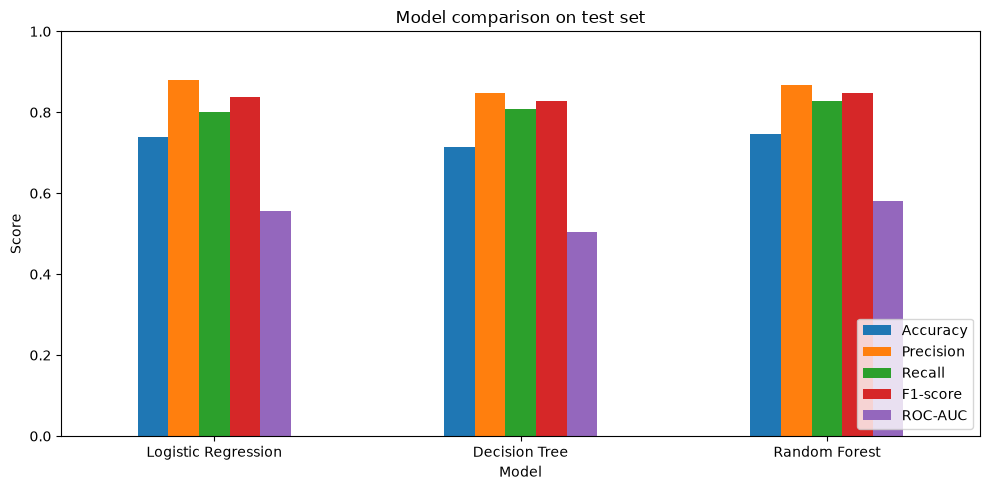

In [7]:
ax = metrics[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), rot=0)
ax.set_ylim(0, 1)
ax.set_title("Model comparison on test set")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

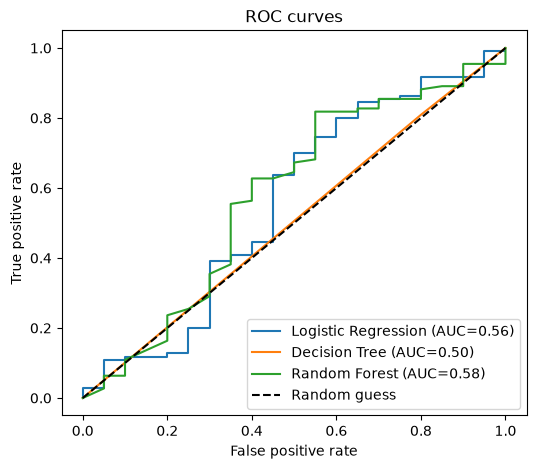

In [8]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs[name]):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves"); plt.legend()
plt.show()

## 6. Best model

In [9]:
best_name = metrics["F1-score"].idxmax()
print("Best model by test F1:", best_name)
print(metrics.loc[best_name])

Best model by test F1: Random Forest
Accuracy                 0.746
Precision                0.867
Recall                   0.827
F1-score                 0.847
ROC-AUC                  0.580
Fail recall              0.300
Balanced acc             0.564
Train F1                 1.000
F1 gap (train - test)    0.153
Name: Random Forest, dtype: float64


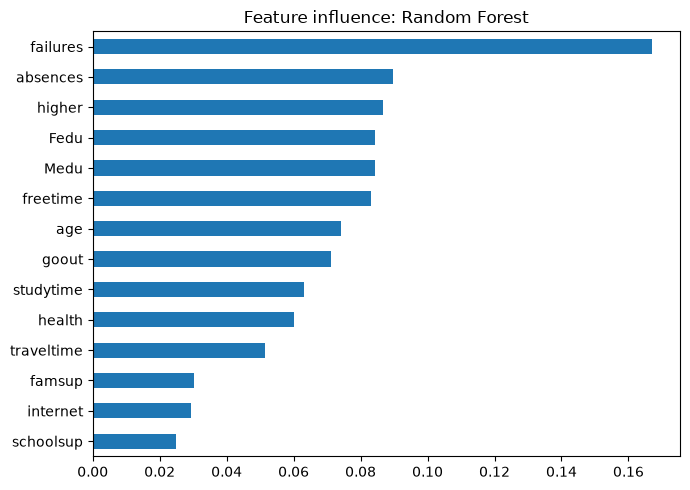

In [10]:
# Which features matter most? (for the best model, if it supports it)
best = models[best_name]
est = best[-1] if hasattr(best, "steps") else best
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=X_test.columns).sort_values()
elif hasattr(est, "coef_"):
    imp = pd.Series(est.coef_[0], index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 5), title=f"Feature influence: {best_name}")
plt.tight_layout()
plt.show()

## 7. Discussion and limitations

**Results (test set, 130 students: 110 Pass, 20 Fail):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Fail recall | Train F1 |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.738 | 0.880 | 0.800 | 0.838 | 0.557 | 0.40 | 0.892 |
| Decision Tree | 0.715 | 0.848 | 0.809 | 0.828 | 0.505 | 0.20 | 1.000 |
| Random Forest | 0.746 | 0.867 | 0.827 | 0.847 | 0.580 | 0.30 | 1.000 |

*(From the saved .pkl files of Member 3. If the models are retrained, re-check these numbers.)*

**Best model:** Random Forest has the highest accuracy (0.746), recall (0.827), F1 (0.847) and ROC-AUC (0.580), so it is the best model **by the F1 metric we tuned for**. Logistic Regression has the best precision (0.880), and it is very close in F1 (0.838 vs 0.847).

**But, be honest about it:**
- If we just predict "Pass" for everyone, accuracy is **0.846**, which is higher than all 3 models. So none of them really beats the baseline on accuracy.
- Random Forest and Decision Tree both have train F1 = 1.000, so they **memorise the training data** (overfit). Logistic Regression has the smallest train-test gap (0.054), so it is the most stable.
- Logistic Regression finds the most failing students (8 of 20, fail recall 0.40, balanced accuracy 0.600). Random Forest finds 6 of 20 and Decision Tree only 4 of 20.
- ROC-AUC of all models is around 0.5-0.6, so they are only slightly better than random guessing. The Decision Tree (0.505) is basically random.
- The difference between Random Forest and Logistic Regression is small (about 0.01 F1) on only 130 test students, so it may not be a real difference.

**Conclusion:** Random Forest is the best on paper (F1), but Logistic Regression is the more reliable and useful choice if we care about finding at-risk students.

**Limitations:**
- **Small dataset:** 649 students, and only 20 Fail in the test set. One student changing class moves the scores a lot.
- **Class imbalance:** 85% pass, so accuracy looks good even for a weak model. Use fail recall, balanced accuracy and the confusion matrix too.
- **Only one split:** a single 80/20 split, so results may change with another random_state.
- **Weak features:** G1 and G2 (earlier grades) were not used, so the model loses the strongest predictors. This is fine for early warning, but it lowers performance.
- **Tuned on F1 of Pass class:** GridSearchCV optimised F1 for Pass, which favours predicting Pass. Tuning for Fail recall or macro F1 may give a better model for at-risk students.
- **One school, one subject:** Portuguese class only, so it may not work for other courses or countries.
- **Prediction, not cause:** features like `studytime` show association only.
- **Self-reported data:** `goout`, `health`, `freetime` are survey answers.

**Future work:** tune with macro F1 or fail recall, try cross-validation on the final models, adjust the decision threshold, try Gradient Boosting, and add G1/G2 or more data.